In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor

# Load our previously saved product dataset
product_sales = pd.read_csv(
    "../data/selected_product_sales.csv",
    parse_dates=["date"]
)

# Assign chronological periods
product_sales["period"] = np.select(
    [
        product_sales["day_number"] <= 1773,
        product_sales["day_number"].between(1774, 1829),
        product_sales["day_number"].between(1830, 1885),
        product_sales["day_number"].between(1886, 1941)
    ],
    ["train", "validation", "calibration", "test"],
    default="unknown"
)

# Calculate zero-sales percentages per product and period
zero_rates = (
    product_sales
    .groupby(["item_id", "period"])["units_sold"]
    .apply(lambda x: (x == 0).mean() * 100)
    .unstack()
)

print(zero_rates.round(2).to_string())


period       calibration   test  train  validation
item_id                                           
FOODS_3_090         0.00   0.00  24.70       55.36
FOODS_3_120        30.36  10.71  36.10        7.14
FOODS_3_252         0.00   0.00   0.28        1.79
FOODS_3_586         0.00   0.00   0.34        1.79
FOODS_3_714         0.00   0.00   0.34        1.79


In [2]:

# Load calendar events
calendar = pd.read_csv(
    "../data/raw/calendar.csv",
    usecols=["d", "event_name_1", "event_name_2"]
)

df = product_sales.merge(
    calendar,
    on="d",
    how="left",
    validate="many_to_one"
)

df = df.sort_values(
    ["item_id", "day_number"]
).reset_index(drop=True)

# Product-specific historical lags
for lag in [1, 7, 14, 28]:
    df[f"lag_{lag}"] = (
        df.groupby("item_id")["units_sold"]
        .shift(lag)
    )

# Product-specific rolling averages
for window in [7, 28]:
    df[f"rolling_mean_{window}"] = (
        df.groupby("item_id")["units_sold"]
        .transform(
            lambda s: s.shift(1).rolling(window).mean()
        )
    )

# Previous 8 observations of the same weekday
weekly_columns = []

for week in range(1, 9):
    col = f"weekly_lag_{week}"
    df[col] = (
        df.groupby("item_id")["units_sold"]
        .shift(7 * week)
    )
    weekly_columns.append(col)

# Seasonal 80th-percentile baseline
df["seasonal_q80"] = df[weekly_columns].quantile(
    0.80, axis=1
)

# Calendar features
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

for col in ["event_name_1", "event_name_2"]:
    df[col] = df[col].fillna("No_Event")

# Model features
numeric_features = [
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

categorical_features = [
    "item_id", "day_of_week", "month",
    "event_name_1", "event_name_2"
]

features = numeric_features + categorical_features

# Remove rows without sufficient history
df = df.dropna(
    subset=features + ["seasonal_q80"]
).copy()

print("Prepared rows:", len(df))
print("Products:", df["item_id"].nunique())


Prepared rows: 9565
Products: 5


In [3]:

train = df[df["day_number"] <= 1773].copy()

validation = df[
    df["day_number"].between(1774, 1829)
].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))

# Prepare numerical and categorical features
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Create a pooled quantile model
pooled_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        objective="quantile",
        alpha=0.80,
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=30,
        random_state=42,
        verbosity=-1
    ))
])

pooled_model.fit(
    train[features],
    train["units_sold"]
)

# Predict order quantities
validation["ml_order"] = np.ceil(
    np.maximum(
        0,
        pooled_model.predict(validation[features])
    )
)

validation["seasonal_order"] = np.ceil(
    np.maximum(0, validation["seasonal_q80"])
)

print("Pooled product forecasting model trained!")


Training rows: 8725
Validation rows: 280


c:\Users\kyan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\kyan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\kyan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\kyan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

Pooled product forecasting model trained!


In [4]:

# Assumed cost parameters
overstock_cost = 2
understock_cost = 8

def calculate_cost(actual, order):
    overstock = np.maximum(order - actual, 0)
    understock = np.maximum(actual - order, 0)

    return (
        overstock_cost * overstock
        + understock_cost * understock
    )

results = []

for product_id, group in validation.groupby("item_id"):

    actual = group["units_sold"].to_numpy()

    ml_order = group["ml_order"].to_numpy()
    seasonal_order = group["seasonal_order"].to_numpy()

    ml_cost = calculate_cost(actual, ml_order).sum()
    seasonal_cost = calculate_cost(
        actual, seasonal_order
    ).sum()

    savings_pct = (
        (seasonal_cost - ml_cost)
        / seasonal_cost * 100
    ) if seasonal_cost > 0 else np.nan

    results.append({
        "Product": product_id,
        "Seasonal Cost": seasonal_cost,
        "ML Cost": ml_cost,
        "Savings (%)": savings_pct
    })

comparison = pd.DataFrame(results)

print(comparison.round(2).to_string(index=False))

# Overall comparison
print("\nTOTAL COSTS")
print(
    "Seasonal Quantile:",
    comparison["Seasonal Cost"].sum()
)
print(
    "Pooled Quantile ML:",
    comparison["ML Cost"].sum()
)


    Product  Seasonal Cost  ML Cost  Savings (%)
FOODS_3_090         5764.0   2016.0        65.02
FOODS_3_120         4656.0   3394.0        27.10
FOODS_3_252         2060.0   1406.0        31.75
FOODS_3_586         1938.0   1604.0        17.23
FOODS_3_714         2054.0   1384.0        32.62

TOTAL COSTS
Seasonal Quantile: 16472.0
Pooled Quantile ML: 9804.0


In [5]:

for product_id in ["FOODS_3_090", "FOODS_3_120"]:

    product = product_sales[
        product_sales["item_id"] == product_id
    ].sort_values("day_number").copy()

    is_zero = product["units_sold"].eq(0)

    # Assign a separate ID to each consecutive run
    run_id = is_zero.ne(is_zero.shift()).cumsum()

    # Summarize runs consisting of zero sales
    zero_runs = (
        product.loc[is_zero]
        .assign(run_id=run_id.loc[is_zero].to_numpy())
        .groupby("run_id")
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            consecutive_days=("date", "size")
        )
        .sort_values("consecutive_days", ascending=False)
        .head(5)
    )

    print(f"\n{product_id} — Longest zero-sales streaks")
    print(zero_runs.to_string(index=False))



FOODS_3_090 — Longest zero-sales streaks
start_date   end_date  consecutive_days
2011-02-08 2011-09-22               227
2014-12-01 2015-01-03                34
2015-12-04 2016-01-06                34
2015-05-14 2015-06-13                31
2014-02-08 2014-03-08                29

FOODS_3_120 — Longest zero-sales streaks
start_date   end_date  consecutive_days
2011-01-29 2012-01-30               367
2012-10-13 2013-02-05               116
2014-02-07 2014-03-02                24
2013-11-03 2013-11-22                20
2016-02-26 2016-03-12                16


In [7]:

# Later-period evaluation
later = df[
    df["day_number"].between(1886, 1941)
].copy()

# Existing pooled model's 80th-percentile forecasts
later["ml_q80"] = np.maximum(
    0,
    pooled_model.predict(later[features])
)

# Convert forecasts into integer order quantities
later["ml_order"] = np.ceil(later["ml_q80"])

later["seasonal_order"] = np.ceil(
    np.maximum(0, later["seasonal_q80"])
)

# Assumed inventory decision costs
def decision_cost(actual, order):
    surplus = np.maximum(order - actual, 0)
    shortage = np.maximum(actual - order, 0)

    return 2 * surplus + 8 * shortage

later["ml_cost"] = decision_cost(
    later["units_sold"], later["ml_order"]
)

later["seasonal_cost"] = decision_cost(
    later["units_sold"], later["seasonal_order"]
)

# Check how often actual sales fall below
# the predicted 80th percentile
later["q80_covered"] = (
    later["units_sold"] <= later["ml_q80"]
)

# Product-level results
results = later.groupby("item_id").agg(
    seasonal_cost=("seasonal_cost", "sum"),
    ml_cost=("ml_cost", "sum"),
    q80_coverage=("q80_covered", "mean")
)

results["savings_pct"] = (
    (results["seasonal_cost"] - results["ml_cost"])
    / results["seasonal_cost"] * 100
)

results["q80_coverage"] *= 100

print("LATER-PERIOD RESULTS")
print(results.round(2).to_string())

# Overall savings
total_seasonal = results["seasonal_cost"].sum()
total_ml = results["ml_cost"].sum()

overall_savings = (
    (total_seasonal - total_ml)
    / total_seasonal * 100
)

print("\nTOTAL SEASONAL COST:", total_seasonal)
print("TOTAL ML COST:", total_ml)
print(f"OVERALL SAVINGS: {overall_savings:.2f}%")
print(f"OVERALL Q80 COVERAGE: {later['q80_covered'].mean()*100:.2f}%")


LATER-PERIOD RESULTS
             seasonal_cost  ml_cost  q80_coverage  savings_pct
item_id                                                       
FOODS_3_090         2668.0   2656.0         83.93         0.45
FOODS_3_120         4204.0   3308.0         80.36        21.31
FOODS_3_252         1684.0   1480.0         85.71        12.11
FOODS_3_586         1260.0   1394.0         80.36       -10.63
FOODS_3_714         1164.0   1056.0         89.29         9.28

TOTAL SEASONAL COST: 10980.0
TOTAL ML COST: 9894.0
OVERALL SAVINGS: 9.89%
OVERALL Q80 COVERAGE: 83.93%


In [8]:

from sklearn.base import clone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Eight consecutive 56-day evaluation windows
cutoffs = [1493, 1549, 1605, 1661,
           1717, 1773, 1829, 1885]

fold_results = []
product_results = []

def inventory_cost(actual, order):
    surplus = np.maximum(order - actual, 0)
    shortage = np.maximum(actual - order, 0)
    return 2 * surplus + 8 * shortage

for fold, cutoff in enumerate(cutoffs, start=1):

    train_fold = df[
        df["day_number"] <= cutoff
    ].copy()

    test_fold = df[
        df["day_number"].between(
            cutoff + 1, cutoff + 56
        )
    ].copy()

    # Fresh model trained only on earlier data
    model = clone(pooled_model)

    model.fit(
        train_fold[features],
        train_fold["units_sold"]
    )

    # Predict the 80th percentile
    q80 = np.maximum(
        0,
        model.predict(test_fold[features])
    )

    actual = test_fold["units_sold"].to_numpy()

    ml_order = np.ceil(q80)
    seasonal_order = np.ceil(
        np.maximum(
            0,
            test_fold["seasonal_q80"].to_numpy()
        )
    )

    ml_costs = inventory_cost(actual, ml_order)
    seasonal_costs = inventory_cost(
        actual, seasonal_order
    )

    ml_total = ml_costs.sum()
    seasonal_total = seasonal_costs.sum()

    savings = (
        (seasonal_total - ml_total)
        / seasonal_total * 100
    )

    fold_results.append({
        "Fold": fold,
        "Start Day": cutoff + 1,
        "End Day": cutoff + 56,
        "ML Cost": ml_total,
        "Seasonal Cost": seasonal_total,
        "Savings (%)": savings,
        "Q80 Coverage (%)": np.mean(
            actual <= q80
        ) * 100
    })

    # Keep results for each product
    temp = test_fold[[
        "item_id", "day_number"
    ]].copy()

    temp["ml_cost"] = ml_costs
    temp["seasonal_cost"] = seasonal_costs

    temp["Fold"] = fold

    product_results.append(temp)

# Summarize results
backtest = pd.DataFrame(fold_results)

print("ROLLING BACKTEST RESULTS")
print(backtest.round(2).to_string(index=False))

total_ml = backtest["ML Cost"].sum()
total_seasonal = backtest["Seasonal Cost"].sum()

overall_savings = (
    (total_seasonal - total_ml)
    / total_seasonal * 100
)

print("\nOVERALL RESULTS")
print(f"Total ML cost: ${total_ml:,.2f}")
print(f"Total Seasonal cost: ${total_seasonal:,.2f}")
print(f"Overall savings: {overall_savings:.2f}%")

print(
    "Folds where ML wins:",
    (backtest["Savings (%)"] > 0).sum(),
    "out of", len(backtest)
)


ROLLING BACKTEST RESULTS
 Fold  Start Day  End Day  ML Cost  Seasonal Cost  Savings (%)  Q80 Coverage (%)
    1       1494     1549  12198.0        14292.0        14.65             80.00
    2       1550     1605  10760.0        16696.0        35.55             80.00
    3       1606     1661  11276.0        14286.0        21.07             79.64
    4       1662     1717  10248.0        10304.0         0.54             84.64
    5       1718     1773  13094.0        16118.0        18.76             80.71
    6       1774     1829   9804.0        16472.0        40.48             83.21
    7       1830     1885  11014.0        13130.0        16.12             80.36
    8       1886     1941  10030.0        10980.0         8.65             81.07

OVERALL RESULTS
Total ML cost: $88,424.00
Total Seasonal cost: $112,278.00
Overall savings: 21.25%
Folds where ML wins: 8 out of 8


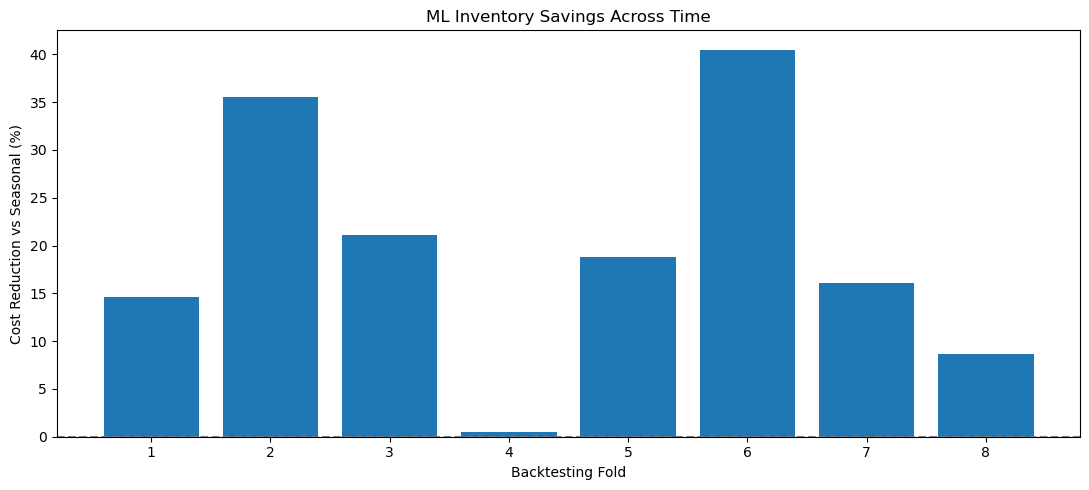

In [9]:

plt.figure(figsize=(11, 5))

plt.bar(
    backtest["Fold"].astype(str),
    backtest["Savings (%)"]
)

plt.axhline(0, linestyle="--", color="gray")

plt.title("ML Inventory Savings Across Time")
plt.xlabel("Backtesting Fold")
plt.ylabel("Cost Reduction vs Seasonal (%)")

plt.tight_layout()
plt.show()


In [10]:

product_backtest = pd.concat(
    product_results,
    ignore_index=True
)

product_summary = (
    product_backtest.groupby("item_id")
    .agg(
        ml_cost=("ml_cost", "sum"),
        seasonal_cost=("seasonal_cost", "sum")
    )
)

product_summary["savings_pct"] = (
    (product_summary["seasonal_cost"]
     - product_summary["ml_cost"])
    / product_summary["seasonal_cost"] * 100
)

print("PRODUCT PERFORMANCE ACROSS ALL FOLDS")
print(product_summary.round(2).to_string())


PRODUCT PERFORMANCE ACROSS ALL FOLDS
             ml_cost  seasonal_cost  savings_pct
item_id                                         
FOODS_3_090  25944.0        37502.0        30.82
FOODS_3_120  27384.0        32360.0        15.38
FOODS_3_252  12544.0        15776.0        20.49
FOODS_3_586  12514.0        14796.0        15.42
FOODS_3_714  10038.0        11844.0        15.25


In [11]:

import pandas as pd

sales_path = "../data/raw/sales_train_evaluation.csv"

# Earliest rolling training cutoff
cutoff = 1493

day_columns = [
    f"d_{i}" for i in range(1, cutoff + 1)
]

columns = [
    "item_id", "store_id", "cat_id"
] + day_columns

candidates = []

for chunk in pd.read_csv(
    sales_path,
    usecols=columns,
    chunksize=250
):
    selected = chunk[
        (chunk["store_id"] == "CA_1") &
        (chunk["cat_id"] == "FOODS")
    ]

    if selected.empty:
        continue

    product_totals = pd.DataFrame({
        "item_id": selected["item_id"],
        "training_sales": selected[day_columns].sum(axis=1)
    })

    candidates.append(product_totals)

ranked = pd.concat(candidates, ignore_index=True)

early_top5 = ranked.nlargest(
    5, "training_sales"
)

print("Top 5 products using days 1–1493:")
print(early_top5.to_string(index=False))

previous_products = {
    "FOODS_3_090",
    "FOODS_3_120",
    "FOODS_3_252",
    "FOODS_3_586",
    "FOODS_3_714"
}

new_products = set(early_top5["item_id"])

print("\nSame five products:",
      previous_products == new_products)

print("Newly selected:", new_products - previous_products)
print("No longer selected:", previous_products - new_products)


Top 5 products using days 1–1493:
    item_id  training_sales
FOODS_3_090          106399
FOODS_3_586           69539
FOODS_3_252           58574
FOODS_3_120           45286
FOODS_3_714           44255

Same five products: True
Newly selected: set()
No longer selected: set()


In [13]:

import pandas as pd

# Load product-level sales
sales = pd.read_csv(
    "../data/selected_product_sales.csv",
    parse_dates=["date"]
)

# Load calendar week identifiers
calendar = pd.read_csv(
    "../data/raw/calendar.csv",
    usecols=["d", "wm_yr_wk"]
)

# Load product selling prices
prices = pd.read_csv(
    "../data/raw/sell_prices.csv",
    usecols=[
        "store_id", "item_id",
        "wm_yr_wk", "sell_price"
    ]
)

# Keep prices from our selected store and products
prices = prices[
    (prices["store_id"] == "CA_1") &
    (prices["item_id"].isin(sales["item_id"].unique()))
].copy()

# Attach weekly calendar identifiers
sales_price = sales.merge(
    calendar,
    on="d",
    how="left",
    validate="many_to_one"
)

# Attach available prices
sales_price = sales_price.merge(
    prices[["item_id", "wm_yr_wk", "sell_price"]],
    on=["item_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one"
)

# Identify zero-sales days and price-record availability
sales_price["zero_sales"] = (
    sales_price["units_sold"] == 0
)

sales_price["price_available"] = (
    sales_price["sell_price"].notna()
)

print("Total observations:", len(sales_price))
print("Price data merged successfully!")


Total observations: 9705
Price data merged successfully!


In [14]:

summary = (
    sales_price
    .groupby(["item_id", "zero_sales"])
    .agg(
        days=("d", "size"),
        price_records=("price_available", "sum")
    )
    .reset_index()
)

summary["price_coverage_pct"] = (
    summary["price_records"] /
    summary["days"] * 100
)

print(
    summary.round(2).to_string(index=False)
)


    item_id  zero_sales  days  price_records  price_coverage_pct
FOODS_3_090       False  1472           1472              100.00
FOODS_3_090        True   469            469              100.00
FOODS_3_120       False  1274           1274              100.00
FOODS_3_120        True   667            303               45.43
FOODS_3_252       False  1935           1935              100.00
FOODS_3_252        True     6              6              100.00
FOODS_3_586       False  1934           1934              100.00
FOODS_3_586        True     7              7              100.00
FOODS_3_714       False  1934           1934              100.00
FOODS_3_714        True     7              7              100.00


In [15]:

for product_id in ["FOODS_3_090", "FOODS_3_120"]:

    p = sales_price[
        sales_price["item_id"] == product_id
    ].sort_values("day_number").copy()

    # Consecutive zero/nonzero run identifiers
    p["run_id"] = (
        p["zero_sales"]
        .ne(p["zero_sales"].shift())
        .cumsum()
    )

    # Analyze only zero-sales streaks
    streaks = (
        p[p["zero_sales"]]
        .groupby("run_id")
        .agg(
            start=("date", "min"),
            end=("date", "max"),
            days=("d", "size"),
            days_with_price=("price_available", "sum")
        )
    )

    streaks["price_coverage_pct"] = (
        streaks["days_with_price"] /
        streaks["days"] * 100
    )

    print(f"\n{product_id}: Longest zero-sales streaks")

    print(
        streaks.nlargest(5, "days")
        .round(2)
        .to_string(index=False)
    )



FOODS_3_090: Longest zero-sales streaks
     start        end  days  days_with_price  price_coverage_pct
2011-02-08 2011-09-22   227              227               100.0
2014-12-01 2015-01-03    34               34               100.0
2015-12-04 2016-01-06    34               34               100.0
2015-05-14 2015-06-13    31               31               100.0
2014-02-08 2014-03-08    29               29               100.0

FOODS_3_120: Longest zero-sales streaks
     start        end  days  days_with_price  price_coverage_pct
2011-01-29 2012-01-30   367                3                0.82
2012-10-13 2013-02-05   116              116              100.00
2014-02-07 2014-03-02    24               24              100.00
2013-11-03 2013-11-22    20               20              100.00
2016-02-26 2016-03-12    16               16              100.00


In [16]:

# Attach prices to the already-featured model dataset
price_lookup = sales_price[
    ["item_id", "d", "sell_price"]
].copy()

df_priced = df.merge(
    price_lookup,
    on=["item_id", "d"],
    how="left",
    validate="one_to_one"
)

df_priced["price_available"] = (
    df_priced["sell_price"].notna()
)

print("Model-ready observations:", len(df_priced))
print(
    "Missing-price observations:",
    (~df_priced["price_available"]).sum()
)

# Check whether missing-price days appear
# in the eight evaluation windows
evaluation_rows = df_priced[
    df_priced["day_number"].between(1494, 1941)
]

print("\nMissing prices during backtesting:")
print(
    evaluation_rows.groupby("item_id")[
        "price_available"
    ].apply(lambda s: (~s).sum())
)


Model-ready observations: 9565
Missing-price observations: 336

Missing prices during backtesting:
item_id
FOODS_3_090    0
FOODS_3_120    0
FOODS_3_252    0
FOODS_3_586    0
FOODS_3_714    0
Name: price_available, dtype: int64


In [17]:

from sklearn.base import clone
import numpy as np
import pandas as pd

cutoffs = [
    1493, 1549, 1605, 1661,
    1717, 1773, 1829, 1885
]

def cost_function(actual, order):
    surplus = np.maximum(order - actual, 0)
    shortage = np.maximum(actual - order, 0)
    return 2 * surplus + 8 * shortage

filtered_results = []

for fold, cutoff in enumerate(cutoffs, start=1):

    # Only train on days with price records
    train_fold = df_priced[
        (df_priced["day_number"] <= cutoff) &
        (df_priced["price_available"])
    ].copy()

    # Keep exactly the same evaluation observations
    test_fold = df_priced[
        df_priced["day_number"].between(
            cutoff + 1, cutoff + 56
        )
    ].copy()

    model = clone(pooled_model)

    model.fit(
        train_fold[features],
        train_fold["units_sold"]
    )

    actual = test_fold["units_sold"].to_numpy()

    ml_order = np.ceil(np.maximum(
        0,
        model.predict(test_fold[features])
    ))

    seasonal_order = np.ceil(np.maximum(
        0,
        test_fold["seasonal_q80"].to_numpy()
    ))

    ml_cost = cost_function(actual, ml_order).sum()
    seasonal_cost = cost_function(
        actual, seasonal_order
    ).sum()

    filtered_results.append({
        "Fold": fold,
        "Training Rows": len(train_fold),
        "ML Cost": ml_cost,
        "Seasonal Cost": seasonal_cost,
        "Savings (%)": (
            (seasonal_cost - ml_cost)
            / seasonal_cost * 100
        )
    })

filtered_backtest = pd.DataFrame(filtered_results)

print("PRICE-FILTERED BACKTEST")
print(filtered_backtest.round(2).to_string(index=False))

total_ml = filtered_backtest["ML Cost"].sum()
total_seasonal = filtered_backtest["Seasonal Cost"].sum()

print(f"\nTotal ML cost: ${total_ml:,.2f}")
print(f"Total Seasonal cost: ${total_seasonal:,.2f}")
print(
    f"Overall savings: "
    f"{(total_seasonal-total_ml)/total_seasonal*100:.2f}%"
)


PRICE-FILTERED BACKTEST
 Fold  Training Rows  ML Cost  Seasonal Cost  Savings (%)
    1           6989  12108.0        14292.0        15.28
    2           7269  10930.0        16696.0        34.54
    3           7549  11104.0        14286.0        22.27
    4           7829  10306.0        10304.0        -0.02
    5           8109  12948.0        16118.0        19.67
    6           8389   9840.0        16472.0        40.26
    7           8669  10994.0        13130.0        16.27
    8           8949   9746.0        10980.0        11.24

Total ML cost: $87,976.00
Total Seasonal cost: $112,278.00
Overall savings: 21.64%


In [18]:

from sklearn.base import clone
import pandas as pd
import numpy as np

# Business cost scenarios
scenarios = [
    ("Equal Costs", 2, 2),
    ("Shortage 4x", 2, 8),
    ("Shortage 9x", 2, 18)
]

cutoffs = [
    1493, 1549, 1605, 1661,
    1717, 1773, 1829, 1885
]

weekly_cols = [
    f"weekly_lag_{i}" for i in range(1, 9)
]

def calculate_inventory_cost(actual, order, over, under):
    surplus = np.maximum(order - actual, 0)
    shortage = np.maximum(actual - order, 0)

    return over * surplus + under * shortage

sensitivity_results = []

for scenario_name, over_cost, under_cost in scenarios:

    # Calculate the optimal target quantile
    q = under_cost / (under_cost + over_cost)

    for fold, cutoff in enumerate(cutoffs, start=1):

        train_fold = df_priced[
            (df_priced["day_number"] <= cutoff) &
            (df_priced["price_available"])
        ].copy()

        test_fold = df_priced[
            df_priced["day_number"].between(
                cutoff + 1, cutoff + 56
            )
        ].copy()

        # Recreate the model for this quantile
        model = clone(pooled_model)
        model.set_params(model__alpha=q)

        model.fit(
            train_fold[features],
            train_fold["units_sold"]
        )

        # Quantile ML forecasts
        ml_predictions = np.maximum(
            0, model.predict(test_fold[features])
        )

        # Seasonal quantile at the SAME target
        seasonal_predictions = (
            test_fold[weekly_cols]
            .quantile(q, axis=1)
            .to_numpy()
        )

        actual = test_fold["units_sold"].to_numpy()

        ml_orders = np.ceil(ml_predictions)
        seasonal_orders = np.ceil(
            np.maximum(0, seasonal_predictions)
        )

        ml_cost = calculate_inventory_cost(
            actual, ml_orders,
            over_cost, under_cost
        ).sum()

        seasonal_cost = calculate_inventory_cost(
            actual, seasonal_orders,
            over_cost, under_cost
        ).sum()

        sensitivity_results.append({
            "Scenario": scenario_name,
            "Fold": fold,
            "Quantile": q,
            "ML Cost": ml_cost,
            "Seasonal Cost": seasonal_cost
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("Cost-sensitivity experiment complete!")


Cost-sensitivity experiment complete!


In [19]:

summary = sensitivity_df.groupby("Scenario").agg(
    ml_cost=("ML Cost", "sum"),
    seasonal_cost=("Seasonal Cost", "sum")
)

summary["savings_pct"] = (
    (summary["seasonal_cost"] - summary["ml_cost"])
    / summary["seasonal_cost"] * 100
)

print("COST SENSITIVITY RESULTS")
print(summary.round(2).to_string())

# Count winning folds in each scenario
sensitivity_df["ml_wins"] = (
    sensitivity_df["ML Cost"] <
    sensitivity_df["Seasonal Cost"]
)

print("\nFOLDS WON")
print(
    sensitivity_df.groupby("Scenario")["ml_wins"].sum()
)


COST SENSITIVITY RESULTS
              ml_cost  seasonal_cost  savings_pct
Scenario                                         
Equal Costs   45152.0        65212.0        30.76
Shortage 4x   87976.0       112278.0        21.64
Shortage 9x  118980.0       156200.0        23.83

FOLDS WON
Scenario
Equal Costs    8
Shortage 4x    7
Shortage 9x    7
Name: ml_wins, dtype: int64


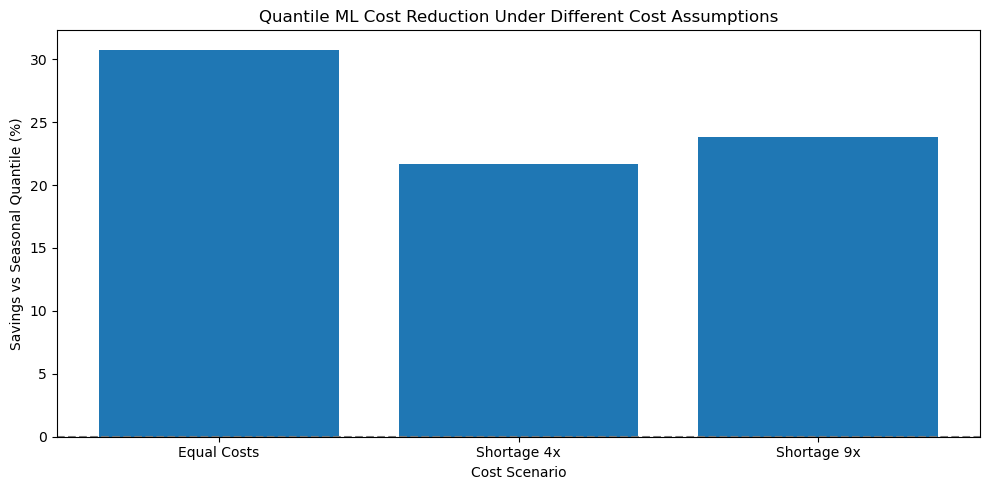

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    summary.index,
    summary["savings_pct"]
)

plt.axhline(0, color="gray", linestyle="--")

plt.title("Quantile ML Cost Reduction Under Different Cost Assumptions")
plt.xlabel("Cost Scenario")
plt.ylabel("Savings vs Seasonal Quantile (%)")
plt.tight_layout()
plt.show()
